In [1]:
import math
import numpy as np

def parse_line(line):
    tokens = line.strip().split()
    cmd = tokens[0]
    params = {t[0]: float(t[1:]) for t in tokens[1:] if t[0] in 'XYZIJR'}
    return cmd, params

def get_nonuniform_t(steps):
    s = np.linspace(0, 1, steps)
    t = 0.5 * (1 - np.cos(np.pi * s))
    return t

def interpret_gcode(gcode_lines, steps_per_segment=50):
    x_ref = 0
    y_ref = 364
    position = {'X': x_ref, 'Y': y_ref}
    points = []

    for line in gcode_lines:
        cmd, params = parse_line(line)

        x1 = params.get('X', position['X'])
        y1 = params.get('Y', position['Y'])

        if cmd in ['G0']:
            # Movimento linear
            x0, y0 = position['X'], position['Y']
            for t in np.linspace(0, 1, steps_per_segment):
                x = x0 + (x1 - x0) * t
                y = y0 + (y1 - y0) * t
                points.append((x, y))
            position.update({'X': x1, 'Y': y1})

        elif cmd in ['G1']:
            # Movimento linear
            x0, y0 = position['X'], position['Y']
            for t in get_nonuniform_t(steps_per_segment):
                x = x0 + (x1 - x0) * t
                y = y0 + (y1 - y0) * t
                points.append((x, y))
            position.update({'X': x1, 'Y': y1})

        elif cmd in ['G2', 'G3']:
            # Movimento circular com I, J
            i = params.get('I', 0.0)
            j = params.get('J', 0.0)
            cx = position['X'] + i
            cy = position['Y'] + j
            x0, y0 = position['X'], position['Y']

            r = math.hypot(x0 - cx, y0 - cy)
            theta0 = math.atan2(y0 - cy, x0 - cx)
            theta1 = math.atan2(y1 - cy, x1 - cx)

            if abs(x1 - x0) < 1e-6 and abs(y1 - y0) < 1e-6:
                # Arco completo
                if cmd == 'G2':
                    theta1 = theta0 - 2 * math.pi
                else:  # G3
                    theta1 = theta0 + 2 * math.pi
            else:
                if cmd == 'G2' and theta1 > theta0:
                    theta1 -= 2 * math.pi
                if cmd == 'G3' and theta1 < theta0:
                    theta1 += 2 * math.pi


            for t in np.linspace(theta0, theta1, steps_per_segment):
                x = cx + r * math.cos(t)
                y = cy + r * math.sin(t)
                points.append((x, y))
            position.update({'X': x1, 'Y': y1})

    return points


In [2]:
gcode = [
    "G0 X182 Y272",
    "G2 X182 Y272 I0 J-80",
    "G0 X182 Y278.6",
    "G1 X107 Y148.7",
    "G1 X257 Y148.7",
    "G1 X182 Y278.6"
]

trajectory = interpret_gcode(gcode)
print(trajectory)

H = 384

[(0.0, 364.0), (3.714285714285714, 362.1224489795918), (7.428571428571428, 360.2448979591837), (11.142857142857142, 358.3673469387755), (14.857142857142856, 356.48979591836735), (18.57142857142857, 354.61224489795916), (22.285714285714285, 352.734693877551), (26.0, 350.85714285714283), (29.71428571428571, 348.9795918367347), (33.42857142857142, 347.1020408163265), (37.14285714285714, 345.2244897959184), (40.857142857142854, 343.3469387755102), (44.57142857142857, 341.46938775510205), (48.28571428571428, 339.59183673469386), (52.0, 337.7142857142857), (55.71428571428571, 335.83673469387753), (59.42857142857142, 333.9591836734694), (63.14285714285714, 332.0816326530612), (66.85714285714285, 330.2040816326531), (70.57142857142857, 328.3265306122449), (74.28571428571428, 326.44897959183675), (78.0, 324.57142857142856), (81.71428571428571, 322.6938775510204), (85.42857142857142, 320.81632653061223), (89.14285714285714, 318.9387755102041), (92.85714285714286, 317.0612244897959), (96.57142857

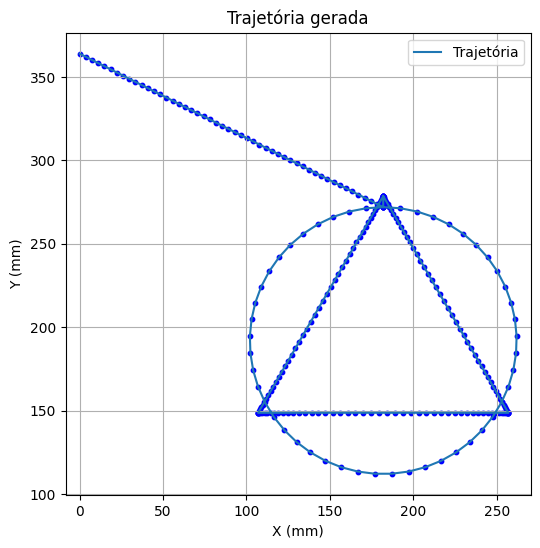

In [3]:
import matplotlib.pyplot as plt

# Separar coordenadas X e Y
x_vals, y_vals = zip(*trajectory)

# Plotar
plt.figure(figsize=(6, 6))
plt.plot(x_vals, y_vals, '-', label='Trajetória')
plt.scatter(x_vals, y_vals, color='blue', s=10)
plt.xlabel('X (mm)')
plt.ylabel('Y (mm)')
plt.title('Trajetória gerada')
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()